In [1]:
!pip install mesa networkx scipy

# **Importing Required Libraries**

In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import seaborn as sns
from scipy import stats

import mesa

from mesa import Agent
from mesa import Model

from mesa.datacollection import DataCollector

print("Mesa Version :", mesa.__version__)

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

# Graph Style
plt.style.use("ggplot")

Mesa Version : 3.5.1


# **Loading Datasets**

In [3]:
# Government Borrowing
debt = pd.read_csv("series-230626.csv")

# Bond Yield
bond = pd.read_csv("BoE-Database_export.csv")

# World Bank Dataset
macro = pd.read_csv(
    "API_GBR_DS2_en_csv_v2_448313.csv",
    skiprows=4
)

print("Debt Shape :", debt.shape)
print("Bond Shape :", bond.shape)
print("Macro Shape:", macro.shape)

Debt Shape : (574, 2)
Bond Shape : (42, 2)
Macro Shape: (1486, 71)


# **Datsets Overview**

In [4]:
print("\nDebt Dataset")
display(debt.head())

print("\nBond Dataset")
display(bond.head())

print("\nWorld Bank Dataset")
display(macro.head())


Debt Dataset


,Title,"Public sector net borrowing, excluding public sector banks (£ million)"
0,CDID,DZLS
1,Source dataset ID,PUSF
2,PreUnit,£
3,Unit,million
4,Release date,19-06-2026



Bond Dataset


,Date,Value
0,31-12-1984,11.4319
1,31-12-1985,11.1617
2,31-12-1986,10.2052
3,31-12-1987,9.7182
4,31-12-1988,9.7938



World Bank Dataset


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,United Kingdom,GBR,"Unemployment, male (% of male labor force) (mo...",SL.UEM.TOTL.MA.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.624,4.217,3.835,4.760,5.083,3.911,4.335,4.568,5.058,NaN
1,United Kingdom,GBR,"Share of youth not in education, employment or...",SL.UEM.NEET.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,12.261,12.333,12.335,12.607,11.410,11.809,12.802,14.300,14.404,NaN
2,United Kingdom,GBR,"Share of youth not in education, employment or...",SL.UEM.NEET.FE.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,12.267,13.037,12.155,11.916,10.490,11.070,12.122,13.090,13.613,NaN
3,United Kingdom,GBR,"Unemployment with intermediate education, fema...",SL.UEM.INTM.FE.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.650,4.372,3.569,4.483,4.766,4.535,4.975,5.286,5.536,NaN
4,United Kingdom,GBR,Unemployment with advanced education (% of tot...,SL.UEM.ADVN.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.733,2.595,2.344,3.238,3.278,2.346,2.598,2.733,3.367,NaN


## **Datsets Information**

In [5]:
print("\nDebt Info")
debt.info()

print("\nBond Info")
bond.info()

print("\nMacro Info")
macro.info()


Debt Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574 entries, 0 to 573
Data columns (total 2 columns):
 #   Column                                                                  Non-Null Count  Dtype 
---  ------                                                                  --------------  ----- 
 0   Title                                                                   574 non-null    object
 1   Public sector net borrowing, excluding public sector banks (£ million)  501 non-null    object
dtypes: object(2)
memory usage: 9.1+ KB

Bond Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    42 non-null     object 
 1   Value   42 non-null     float64
dtypes: float64(1), object(1)
memory usage: 804.0+ bytes

Macro Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1486 entries, 0 to 1485
Data columns (total 71 columns):
 #   Col

## **Missing vlaue Checking for Each Datasets**

In [6]:
print("\nMissing Values")

print(debt.isnull().sum())

print(bond.isnull().sum())

print(macro.isnull().sum())


Missing Values
Title                                                                      0
Public sector net borrowing, excluding public sector banks (£ million)    73
dtype: int64
Date     0
Value    0
dtype: int64
Country Name         0
Country Code         0
Indicator Name       0
Indicator Code       0
1960              1311
                  ... 
2022               673
2023               738
2024               865
2025              1360
Unnamed: 70       1486
Length: 71, dtype: int64


## **Duplicate Value Checking**

In [7]:
print("\nDuplicates")

print("Debt :", debt.duplicated().sum())

print("Bond :", bond.duplicated().sum())

print("Macro :", macro.duplicated().sum())


Duplicates
Debt : 0
Bond : 0
Macro : 0


# **Data Cleaning**

## **Government Borrowing Data Cleaning**

In [8]:
debt.columns=["Year","Government_Borrowing"]

debt=debt[
    debt["Year"].astype(str).str.match(r"^\d{4}$")
]

debt["Year"]=debt["Year"].astype(int)

debt["Government_Borrowing"]=pd.to_numeric(
    debt["Government_Borrowing"],
    errors="coerce"
)

debt=debt.dropna()

debt.reset_index(drop=True,inplace=True)

display(debt.head())

,Year,Government_Borrowing
0,1997,19381.0
1,1998,3875.0
2,1999,-7654.0
3,2000,-16426.0
4,2001,-3107.0


## **Bond Yield Data Cleaning**

In [9]:
bond.columns=["Date","Bond_Yield"]

bond["Date"]=pd.to_datetime(
    bond["Date"],
    dayfirst=True
)

bond["Year"]=bond["Date"].dt.year

bond_yearly=(
    bond.groupby("Year")
    ["Bond_Yield"]
    .mean()
    .reset_index()
)

display(bond_yearly.head())

,Year,Bond_Yield
0,1984,11.4319
1,1985,11.1617
2,1986,10.2052
3,1987,9.7182
4,1988,9.7938


## **World Bank Indicator Selection**

In [10]:
print("Number of Indicators :", macro["Indicator Name"].nunique())

display(
    macro[["Indicator Name","Indicator Code"]]
    .drop_duplicates()
    .sort_values("Indicator Name")
)

Number of Indicators : 1486


,Indicator Name,Indicator Code
879,ARI treatment (% of children under 5 taken to ...,SH.STA.ARIC.ZS
1087,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.ZS
726,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.RU.ZS
1450,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.UR.ZS
1086,Access to electricity (% of population),EG.ELC.ACCS.ZS
...,...,...
1363,Women who believe a husband is justified in be...,SG.VAW.REFU.ZS
786,Women who were first married by age 15 (% of w...,SP.M15.2024.FE.ZS
168,Women who were first married by age 18 (% of w...,SP.M18.2024.FE.ZS
1357,Women's share of population ages 15+ living wi...,SH.DYN.AIDS.FE.ZS


## **Extracting Required Indicators**

In [11]:
required = [

    "GDP (current US$)",

    "Inflation, consumer prices (annual %)",

    "Unemployment, total (% of total labor force) (modeled ILO estimate)",

    "Population, total",

    "General government final consumption expenditure (% of GDP)"

]

macro = macro[
    macro["Indicator Name"].isin(required)
]

print(macro.shape)

display(macro.head())

(5, 71)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
369,United Kingdom,GBR,"Population, total",SP.POP.TOTL,5.240000e+07,5.280000e+07,5.325000e+07,5.365000e+07,5.400000e+07,5.434805e+07,...,6.596600e+07,6.628900e+07,6.663100e+07,6.674400e+07,6.698400e+07,6.760400e+07,6.849200e+07,6.922600e+07,NaN,NaN
406,United Kingdom,GBR,GDP (current US$),NY.GDP.MKTP.CD,7.323397e+10,7.774197e+10,8.124756e+10,8.656196e+10,9.440756e+10,1.018248e+11,...,2.699118e+12,2.897028e+12,2.875710e+12,2.724001e+12,3.194559e+12,3.181244e+12,3.420797e+12,3.686033e+12,NaN,NaN
985,United Kingdom,GBR,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1.003576e+00,3.447496e+00,4.196499e+00,2.018544e+00,3.281587e+00,4.773775e+00,...,2.557756e+00,2.292840e+00,1.738105e+00,9.894867e-01,2.518371e+00,7.922049e+00,6.793967e+00,3.271573e+00,NaN,NaN
1008,United Kingdom,GBR,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.501000e+00,4.145000e+00,3.657000e+00,4.472000e+00,4.864000e+00,3.768000e+00,4.025000e+00,4.361000e+00,4.746,NaN
1305,United Kingdom,GBR,General government final consumption expenditu...,NE.CON.GOVT.ZS,1.756838e+01,1.759395e+01,1.791202e+01,1.721476e+01,1.681183e+01,1.760877e+01,...,1.852818e+01,1.837689e+01,1.893473e+01,2.238497e+01,2.190238e+01,2.038754e+01,2.024138e+01,NaN,NaN,NaN


In [12]:
# REQUIRED YEARS

years = [str(i) for i in range(1997,2026)]

columns = [

    "Indicator Name"

] + years

macro = macro[columns]

display(macro.head())

,Indicator Name,1997,1998,1999,2000,2001,2002,2003,2004,2005,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
369,"Population, total",5.831695e+07,5.848714e+07,5.868247e+07,5.889251e+07,5.911967e+07,5.937048e+07,5.964758e+07,5.998790e+07,6.040121e+07,...,6.560700e+07,6.596600e+07,6.628900e+07,6.663100e+07,6.674400e+07,6.698400e+07,6.760400e+07,6.849200e+07,6.922600e+07,NaN
406,GDP (current US$),1.569317e+12,1.660821e+12,1.693459e+12,1.671598e+12,1.656171e+12,1.790537e+12,2.061228e+12,2.429775e+12,2.551362e+12,...,2.706808e+12,2.699118e+12,2.897028e+12,2.875710e+12,2.724001e+12,3.194559e+12,3.181244e+12,3.420797e+12,3.686033e+12,NaN
985,"Inflation, consumer prices (annual %)",2.201143e+00,1.820562e+00,1.752951e+00,1.182956e+00,1.532350e+00,1.520402e+00,1.376500e+00,1.390398e+00,2.089136e+00,...,1.008417e+00,2.557756e+00,2.292840e+00,1.738105e+00,9.894867e-01,2.518371e+00,7.922049e+00,6.793967e+00,3.271573e+00,NaN
1008,"Unemployment, total (% of total labor force) (...",7.072000e+00,6.198000e+00,6.042000e+00,5.558000e+00,4.696000e+00,5.037000e+00,4.807000e+00,4.594000e+00,4.884000e+00,...,4.909000e+00,4.501000e+00,4.145000e+00,3.657000e+00,4.472000e+00,4.864000e+00,3.768000e+00,4.025000e+00,4.361000e+00,4.746
1305,General government final consumption expenditu...,1.595678e+01,1.597092e+01,1.639835e+01,1.658054e+01,1.719737e+01,1.809005e+01,1.877597e+01,1.933416e+01,1.953459e+01,...,1.909261e+01,1.852818e+01,1.837689e+01,1.893473e+01,2.238497e+01,2.190238e+01,2.038754e+01,2.024138e+01,NaN,NaN


## **Transpose Dataset**

In [13]:
macro = macro.set_index("Indicator Name")

macro = macro.T

macro.reset_index(inplace=True)

macro.rename(
    columns={"index":"Year"},
    inplace=True
)

display(macro.head())

Indicator Name,Year,"Population, total",GDP (current US$),"Inflation, consumer prices (annual %)","Unemployment, total (% of total labor force) (modeled ILO estimate)",General government final consumption expenditure (% of GDP)
0,1997,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,59119673.0,1.656171e+12,1.532350,4.696,17.197373


## **Renaming Columns**

In [14]:
macro.columns = [

    "Year",

    "GDP",

    "Inflation",

    "Unemployment",

    "Population",

    "Government_Expenditure"

]

display(macro.head())

,Year,GDP,Inflation,Unemployment,Population,Government_Expenditure
0,1997,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,59119673.0,1.656171e+12,1.532350,4.696,17.197373


# **Converting data**

In [15]:
macro["Year"] = macro["Year"].astype(int)

for col in macro.columns[1:]:

    macro[col] = pd.to_numeric(

        macro[col],

        errors="coerce"

    )

print(macro.info())

display(macro.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Year                    29 non-null     int64  
 1   GDP                     28 non-null     float64
 2   Inflation               28 non-null     float64
 3   Unemployment            28 non-null     float64
 4   Population              29 non-null     float64
 5   Government_Expenditure  27 non-null     float64
dtypes: float64(5), int64(1)
memory usage: 1.5 KB
None


,Year,GDP,Inflation,Unemployment,Population,Government_Expenditure
0,1997,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,59119673.0,1.656171e+12,1.532350,4.696,17.197373


## **Handling Missing Values**

In [16]:
print(macro.isnull().sum())

macro = macro.fillna(method="ffill")

macro = macro.fillna(method="bfill")

print(macro.isnull().sum())

Year                      0
GDP                       1
Inflation                 1
Unemployment              1
Population                0
Government_Expenditure    2
dtype: int64
Year                      0
GDP                       0
Inflation                 0
Unemployment              0
Population                0
Government_Expenditure    0
dtype: int64


# **Merging all Three datasets**

In [17]:
master = debt.merge(

    bond_yearly,

    on="Year",

    how="inner"

)

master = master.merge(

    macro,

    on="Year",

    how="inner"

)

print(master.shape)

display(master.head())

display(master.tail())

(29, 8)


,Year,Government_Borrowing,Bond_Yield,GDP,Inflation,Unemployment,Population,Government_Expenditure
0,1997,19381.0,7.0491,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,3875.0,5.5465,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,-7654.0,5.1028,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,-16426.0,5.3289,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,-3107.0,4.9279,59119673.0,1.656171e+12,1.532350,4.696,17.197373


,Year,Government_Borrowing,Bond_Yield,GDP,Inflation,Unemployment,Population,Government_Expenditure
24,2021,161122.0,0.7898,66984000.0,3.194559e+12,2.518371,4.864,21.902377
25,2022,108131.0,2.4532,67604000.0,3.181244e+12,7.922049,3.768,20.387540
26,2023,143576.0,4.0692,68492000.0,3.420797e+12,6.793967,4.025,20.241381
27,2024,152004.0,4.1430,69226000.0,3.686033e+12,3.271573,4.361,20.241381
28,2025,147593.0,4.5833,69226000.0,3.686033e+12,3.271573,4.746,20.241381


## **Saving Merging Final Dataset**

In [18]:
master.to_csv("master_dataset.csv", index=False)

## **Dtaset Information**

In [19]:
print(master.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Year                    29 non-null     int64  
 1   Government_Borrowing    29 non-null     float64
 2   Bond_Yield              29 non-null     float64
 3   GDP                     29 non-null     float64
 4   Inflation               29 non-null     float64
 5   Unemployment            29 non-null     float64
 6   Population              29 non-null     float64
 7   Government_Expenditure  29 non-null     float64
dtypes: float64(7), int64(1)
memory usage: 1.9 KB
None


In [20]:
master.describe()

,Year,Government_Borrowing,Bond_Yield,GDP,Inflation,Unemployment,Population,Government_Expenditure
count,29.000000,29.000000,29.000000,2.900000e+01,2.900000e+01,29.000000,29.000000,29.000000
mean,2011.000000,82766.000000,3.492731,6.329347e+07,2.623254e+12,2.434094,5.544379,19.367963
std,8.514693,65074.054079,1.723143,3.521786e+06,6.049423e+11,1.584726,1.371163,1.720942
min,1997.000000,-16426.000000,0.374100,5.831695e+07,1.569317e+12,0.368047,3.657000,15.956784
25%,2004.000000,43613.000000,1.916200,5.998790e+07,2.429358e+12,1.520402,4.594000,18.528177
50%,2011.000000,67828.000000,4.069200,6.325881e+07,2.719558e+12,2.201143,5.037000,19.592725
75%,2018.000000,130512.000000,4.880600,6.628900e+07,2.945580e+12,2.557756,6.198000,20.270350
max,2025.000000,269984.000000,7.049100,6.922600e+07,3.686033e+12,7.922049,8.279000,22.384973


# **Exploratory Data Analysis (EDA)**

## **Correlation Matrix**

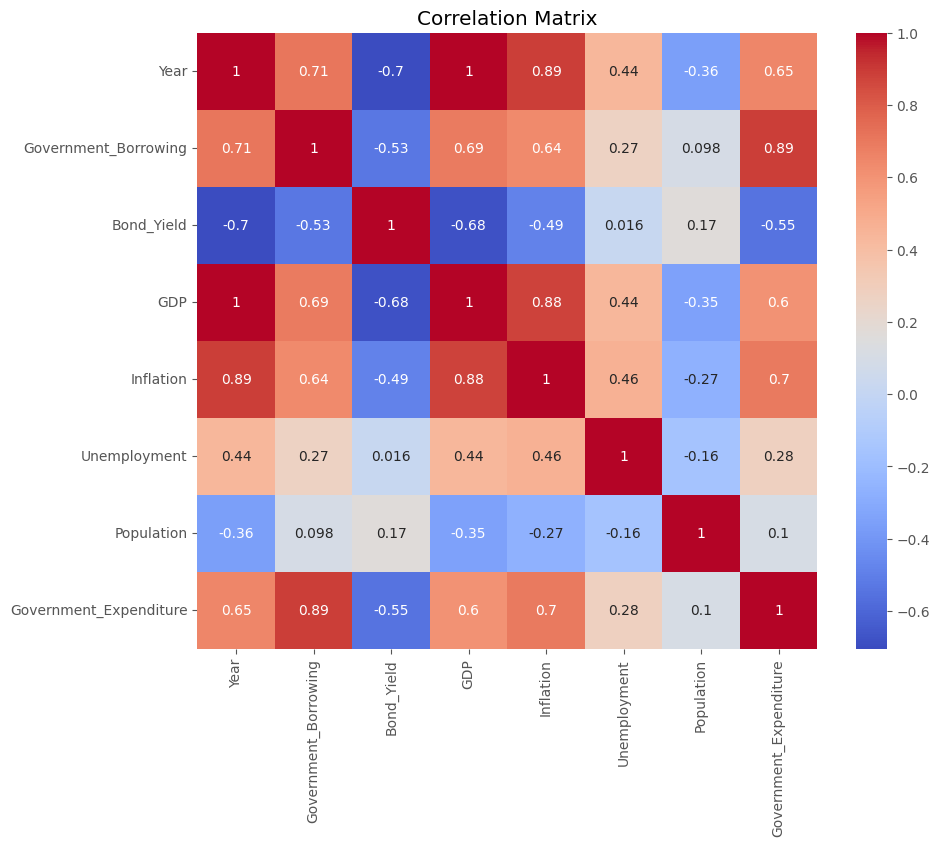

In [21]:
plt.figure(figsize=(10,8))

sns.heatmap(
    master.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

## **Government Borrowing Trend**

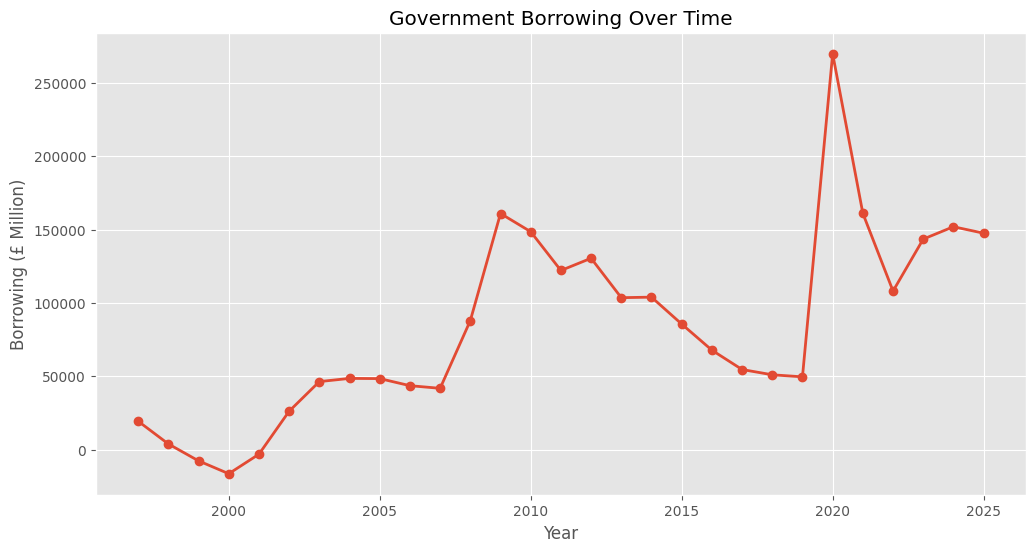

In [22]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Government_Borrowing"],
    marker="o",
    linewidth=2
)

plt.title("Government Borrowing Over Time")

plt.xlabel("Year")

plt.ylabel("Borrowing (£ Million)")

plt.grid(True)

plt.show()

## **Bond Yield Trend**


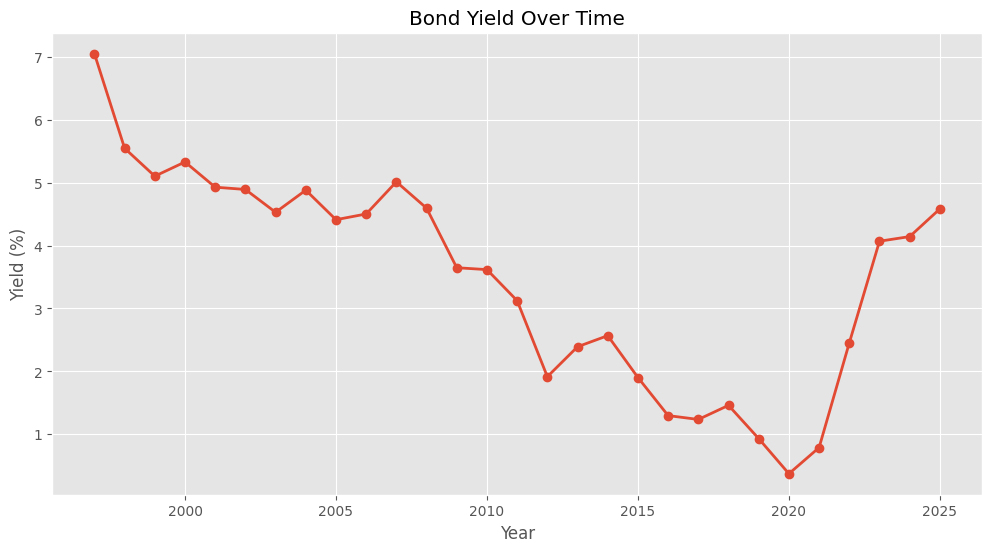

In [23]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Bond_Yield"],
    marker="o",
    linewidth=2
)

plt.title("Bond Yield Over Time")

plt.xlabel("Year")

plt.ylabel("Yield (%)")

plt.grid(True)

plt.show()

## **GDP Trend**

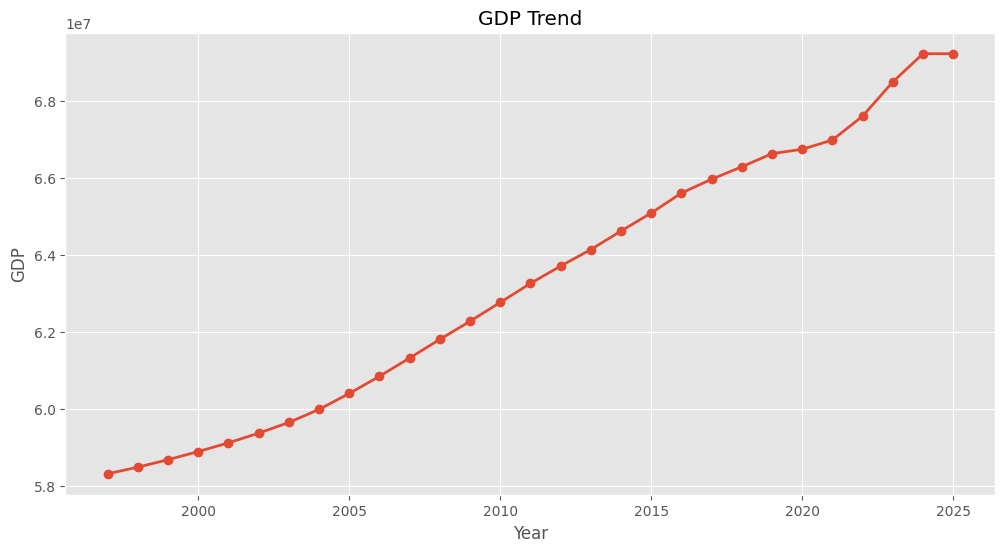

In [24]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["GDP"],
    marker="o",
    linewidth=2
)

plt.title("GDP Trend")

plt.xlabel("Year")

plt.ylabel("GDP")

plt.grid(True)

plt.show()

## **Inflation Trend**

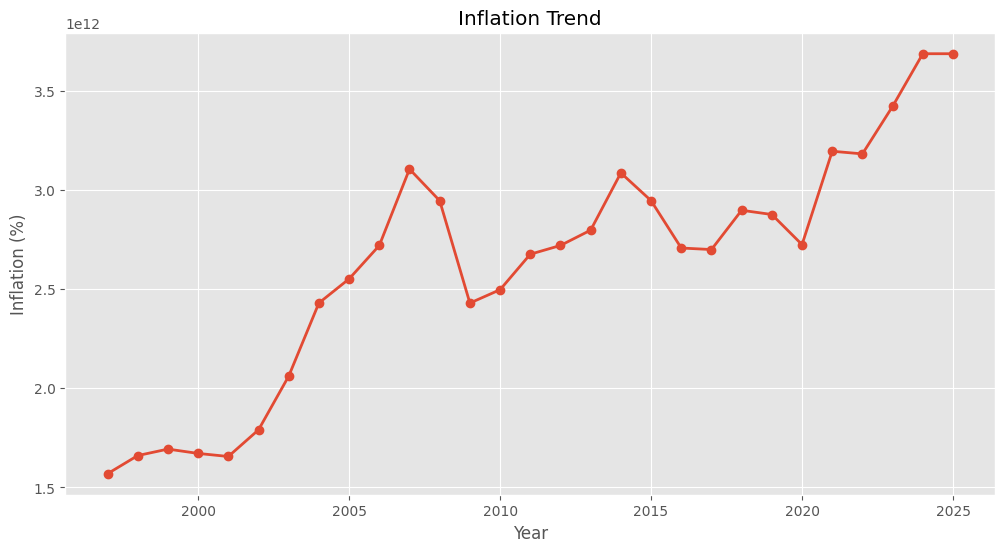

In [25]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Inflation"],
    marker="o",
    linewidth=2
)

plt.title("Inflation Trend")

plt.xlabel("Year")

plt.ylabel("Inflation (%)")

plt.grid(True)

plt.show()

## **Unemployment Trend**

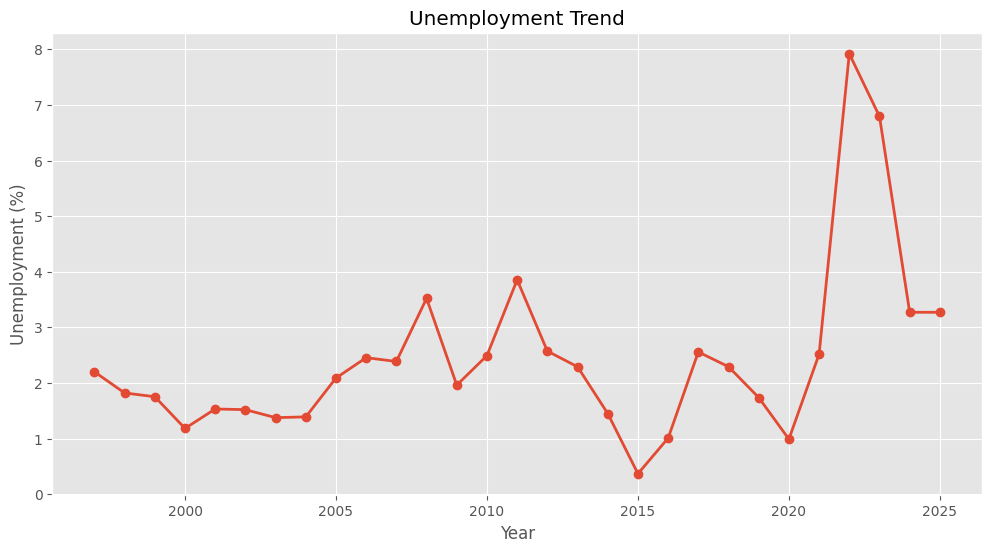

In [26]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Unemployment"],
    marker="o",
    linewidth=2
)

plt.title("Unemployment Trend")

plt.xlabel("Year")

plt.ylabel("Unemployment (%)")

plt.grid(True)

plt.show()

## **Distribution of Variables**

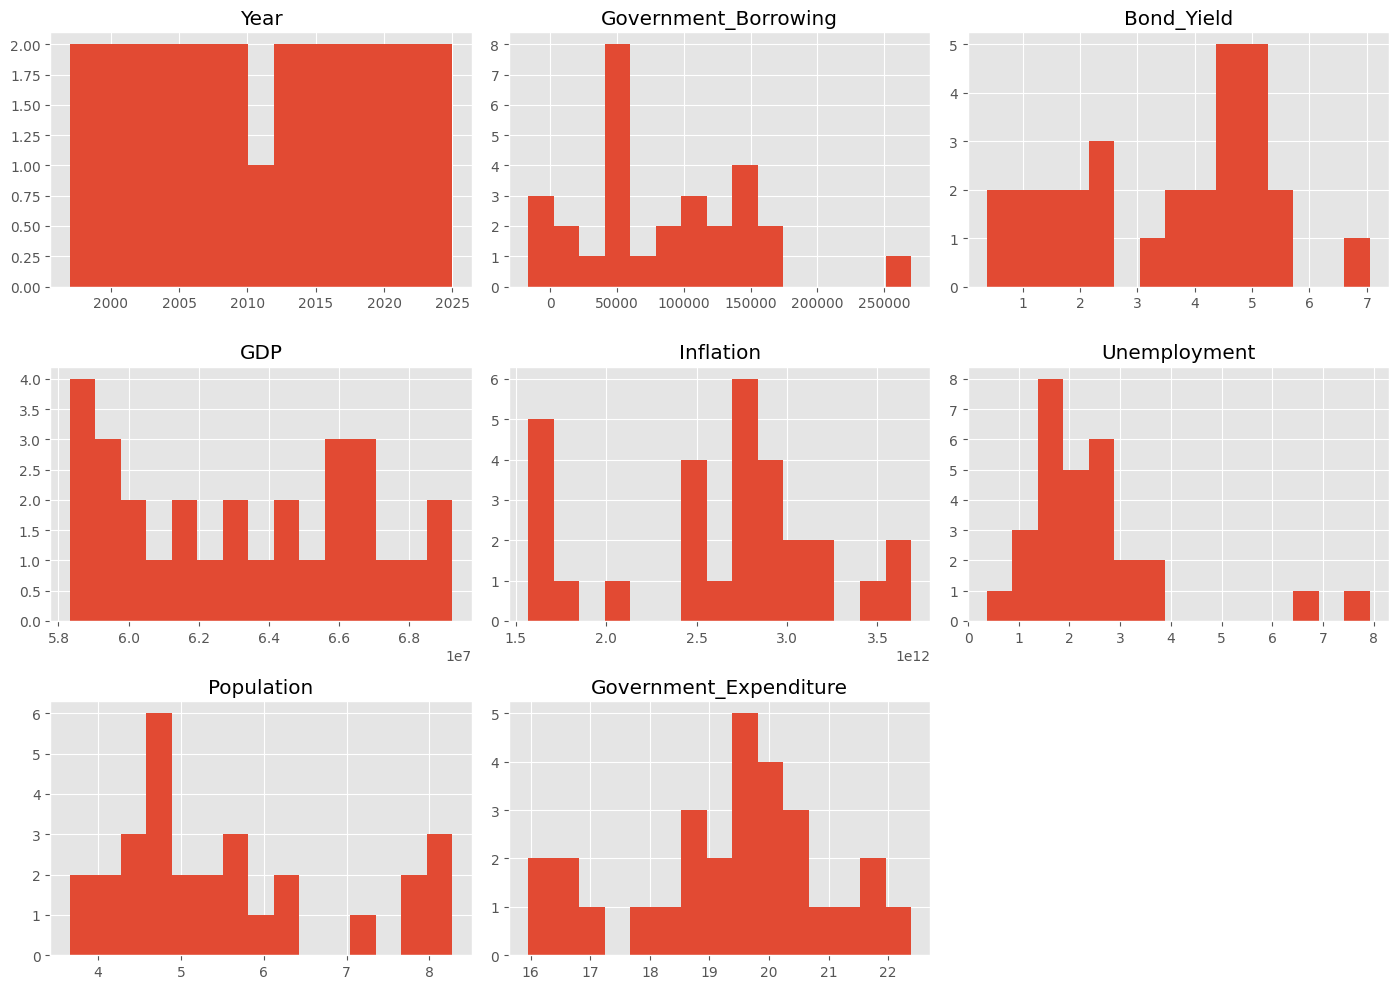

In [27]:
master.hist(
    figsize=(14,10),
    bins=15
)

plt.tight_layout()

plt.show()

## **Boxplots of Numerical Variables**

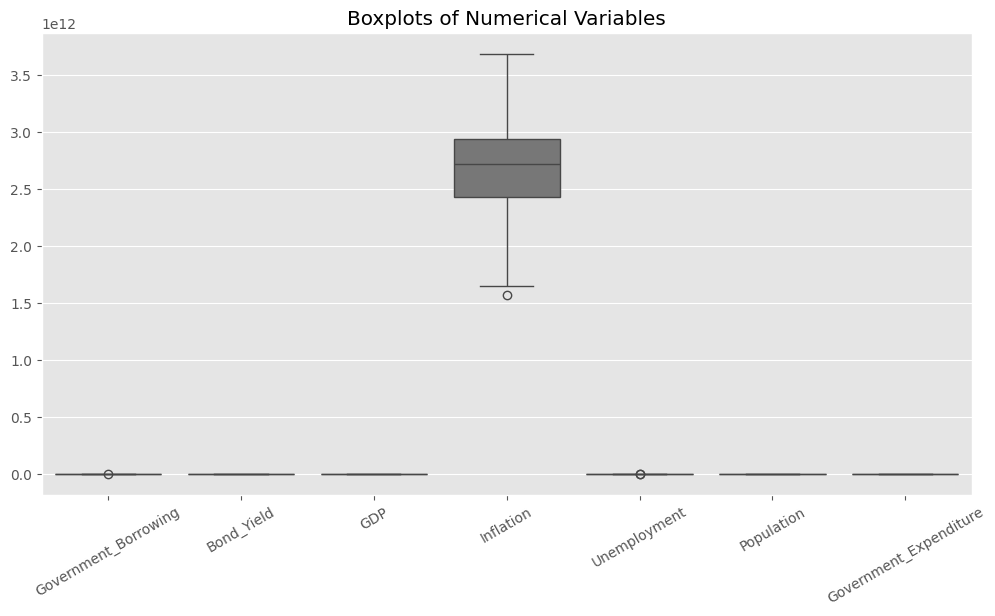

In [28]:
plt.figure(figsize=(12,6))

sns.boxplot(data=master.drop(columns=["Year"]))

plt.xticks(rotation=30)

plt.title("Boxplots of Numerical Variables")

plt.show()

# **Agent-Based Economic Simulation**

## **Simulation Parameters**

In [29]:
BASE_SEED = 42

NUM_BANKS = 5
NUM_INVESTORS = 20
NUM_HOUSEHOLDS = 100

SIMULATION_STEPS = 50

MONTE_CARLO_RUNS = 100

INITIAL_GOVERNMENT_DEBT = float(
    master["Government_Borrowing"].iloc[-1]
)

INITIAL_BOND_YIELD = float(
    master["Bond_Yield"].iloc[-1]
)

# Bank parameters
BANK_INITIAL_CAPITAL = 5_000_000
BANK_BOND_BUDGET = 1_000_000

# Investor parameters
INVESTOR_INITIAL_WEALTH = 100_000
INVESTOR_RISK_APPETITE = 0.60

# Household parameters
HOUSEHOLD_INITIAL_WEALTH = 50_000
HOUSEHOLD_INCOME = 3_000
HOUSEHOLD_CONSUMPTION_RATE = 0.70

# Government bond parameters
NEW_BONDS_PER_STEP = 10_000
INTEREST_PAYMENT_RATE = 0.03

print("=" * 60)
print("SIMULATION PARAMETERS")
print("=" * 60)

print("Banks              :", NUM_BANKS)
print("Investors          :", NUM_INVESTORS)
print("Households         :", NUM_HOUSEHOLDS)
print("Simulation Steps   :", SIMULATION_STEPS)
print("Monte Carlo Runs   :", MONTE_CARLO_RUNS)
print("Base Seed          :", BASE_SEED)

print()
print("Initial Government Debt :", INITIAL_GOVERNMENT_DEBT)
print("Initial Bond Yield      :", INITIAL_BOND_YIELD)

SIMULATION PARAMETERS
Banks              : 5
Investors          : 20
Households         : 100
Simulation Steps   : 50
Monte Carlo Runs   : 100
Base Seed          : 42

Initial Government Debt : 147593.0
Initial Bond Yield      : 4.5833


### **Experimental Design**

In [30]:
experiment_design = pd.DataFrame({

    "Parameter": [
        "Banks",
        "Investors",
        "Households",
        "Simulation Steps",
        "Monte Carlo Runs",
        "Base Seed",
        "Initial Government Debt",
        "Initial Bond Yield",
        "Bond Issuance per Step",
        "Interest Rate"
    ],

    "Value": [
        NUM_BANKS,
        NUM_INVESTORS,
        NUM_HOUSEHOLDS,
        SIMULATION_STEPS,
        MONTE_CARLO_RUNS,
        BASE_SEED,
        INITIAL_GOVERNMENT_DEBT,
        INITIAL_BOND_YIELD,
        NEW_BONDS_PER_STEP,
        INTEREST_PAYMENT_RATE
    ]
})

display(experiment_design)

,Parameter,Value
0,Banks,5.0000
1,Investors,20.0000
2,Households,100.0000
3,Simulation Steps,50.0000
4,Monte Carlo Runs,100.0000
5,Base Seed,42.0000
6,Initial Government Debt,147593.0000
7,Initial Bond Yield,4.5833
8,Bond Issuance per Step,10000.0000
9,Interest Rate,0.0300


## **Government Agent**

In [31]:
class GovernmentAgent(Agent):

    def __init__(self):

        self.debt = INITIAL_GOVERNMENT_DEBT

        self.bond_yield = INITIAL_BOND_YIELD

        self.total_bonds = 0

        self.interest_paid = 0


        self.last_action = None


    def issue_bonds(self):

        self.total_bonds += NEW_BONDS_PER_STEP

        self.debt += NEW_BONDS_PER_STEP

        self.last_action = "Issue Bonds"


    def pay_interest(self):

        self.interest_paid = (
            self.debt
            * INTEREST_PAYMENT_RATE
        )

        self.debt += self.interest_paid

        self.last_action = "Pay Interest"


    def update_bond_yield(self):

        shock = np.random.uniform(
            -0.05,
            0.05
        )

        self.bond_yield += shock

        self.bond_yield = max(
            0,
            self.bond_yield
        )


    def step(self):

        self.issue_bonds()

        self.pay_interest()

        self.update_bond_yield()

## **Bank Agent**

In [32]:
class BankAgent(Agent):

    def __init__(self, bank_id):

        self.bank_id = bank_id

        self.capital = BANK_INITIAL_CAPITAL

        self.bonds_owned = 0

        self.interest_income = 0

        # Behaviour tracking
        self.last_action = None

        self.last_investment = 0


    def buy_bonds(self, government):

        self.last_investment = 0

        investment = min(
            BANK_BOND_BUDGET,
            self.capital * 0.20
        )

        if investment > 0:

            self.capital -= investment

            bonds = investment / 100

            self.bonds_owned += bonds

            self.last_investment = investment

            self.last_action = "Buy Bonds"

        else:

            self.last_action = "Hold"


    def receive_interest(self, government):

        self.interest_income = (

            self.bonds_owned
            * government.bond_yield
            / 100

        )

        self.capital += self.interest_income


    def step(self, government):

        self.buy_bonds(government)

        self.receive_interest(government)

In [33]:
# Testing
gov = GovernmentAgent()

bank = BankAgent(1)

print("Capital Before :", bank.capital)

bank.step(gov)

print("Capital After :", bank.capital)

print("Bonds Owned :", bank.bonds_owned)

print("Interest Income :", bank.interest_income)

Capital Before : 5000000
Capital After : 4000458.33
Bonds Owned : 10000.0
Interest Income : 458.3300000000001


## **Investor Agent**

In [34]:
class InvestorAgent(Agent):

    def __init__(self, investor_id):

        self.investor_id = investor_id

        self.wealth = INVESTOR_INITIAL_WEALTH

        self.bonds_owned = 0

        self.interest_income = 0

        self.risk_appetite = np.random.uniform(
            0.30,
            0.90
        )

        # Behaviour tracking
        self.last_action = None

        self.last_investment = 0


    def decide_investment(self, government):

        self.last_investment = 0

        if government.bond_yield > 2:

            investment = (
                self.wealth
                * self.risk_appetite
                * 0.20
            )

            investment = min(
                investment,
                self.wealth
            )

            self.wealth -= investment

            bonds = investment / 100

            self.bonds_owned += bonds

            self.last_investment = investment

            self.last_action = "Buy Bonds"

        else:

            self.last_action = "Hold"


    def receive_interest(self, government):

        self.interest_income = (

            self.bonds_owned
            * government.bond_yield
            / 100

        )

        self.wealth += self.interest_income


    def step(self, government):

        self.decide_investment(
            government
        )

        self.receive_interest(
            government
        )

In [35]:
# Testing

gov = GovernmentAgent()

investor = InvestorAgent(1)

print("Initial Wealth :", investor.wealth)

investor.step(gov)

print("Updated Wealth :", investor.wealth)

print("Bonds Owned :", investor.bonds_owned)

print("Interest Income :", investor.interest_income)

Initial Wealth : 100000
Updated Wealth : 88346.5906583526
Bonds Owned : 116.58752897863093
Interest Income : 5.343556215677592


## **Household Agent**

In [36]:
class HouseholdAgent(Agent):

    def __init__(self, household_id):

        self.household_id = household_id
        self.wealth = HOUSEHOLD_INITIAL_WEALTH
        self.income = HOUSEHOLD_INCOME
        self.savings = 0
        self.consumption = 0
        self.bonds_owned = 0

        # Behaviour tracking
        self.last_action = None
        self.last_investment = 0

    def earn_income(self):

        self.wealth += self.income

    def consume(self):

        self.consumption = (
            self.income
            * HOUSEHOLD_CONSUMPTION_RATE
        )

        self.wealth -= self.consumption

    def save(self):

        self.savings = (
            self.income
            * (1 - HOUSEHOLD_CONSUMPTION_RATE)
        )

        self.wealth += self.savings

    def invest(self, government):

        self.last_investment = 0

        investment = self.savings * 0.10

        if investment > 0:

            self.wealth -= investment

            bonds = investment / 100

            self.bonds_owned += bonds

            self.last_investment = investment

            self.last_action = "Invest"

        else:

            self.last_action = "Save"

    def step(self, government):

        self.earn_income()
        self.consume()
        self.save()
        self.invest(government)

In [37]:
# Testing

gov = GovernmentAgent()

house = HouseholdAgent(1)

print("Initial Wealth :", house.wealth)

house.step(gov)

print("Updated Wealth :", house.wealth)

print("Savings :", house.savings)

print("Consumption :", house.consumption)

Initial Wealth : 50000
Updated Wealth : 51710.0
Savings : 900.0000000000001
Consumption : 2100.0


## **UK Debt Simulation Model**

In [38]:
class UKDebtModel(Model):

    def __init__(self):

        # GOVERNMENT AGENT

        self.government = GovernmentAgent()


        # BANK AGENTS

        self.banks = [

            BankAgent(i)

            for i in range(NUM_BANKS)
        ]


        # INVESTOR AGENTS

        self.investors = [

            InvestorAgent(i)

            for i in range(NUM_INVESTORS)
        ]

        # HOUSEHOLD AGENTS

        self.households = [

            HouseholdAgent(i)

            for i in range(NUM_HOUSEHOLDS)
        ]

        # MODEL STATE HISTORY

        self.debt_history = []

        self.yield_history = []

        self.bank_capital_history = []

        self.household_wealth_history = []

        self.investor_wealth_history = []

        # AGENT BEHAVIOUR HISTORY

        self.bank_investment_history = []

        self.investor_investment_history = []

        self.household_investment_history = []

        self.interest_payment_history = []

        # ACTION COUNTS

        self.bank_buyers_history = []

        self.investor_buyers_history = []

        self.household_investors_history = []


    def step(self):

        # GOVERNMENT

        self.government.step()


        # BANKS

        for bank in self.banks:

            bank.step(
                self.government
            )


        # INVESTORS

        for investor in self.investors:

            investor.step(
                self.government
            )


        # HOUSEHOLDS

        for household in self.households:

            household.step(
                self.government
            )


        # GOVERNMENT STATE

        self.debt_history.append(
            self.government.debt
        )

        self.yield_history.append(
            self.government.bond_yield
        )


        # BANK STATE

        self.bank_capital_history.append(

            np.mean([
                b.capital
                for b in self.banks
            ])
        )


        # HOUSEHOLD STATE

        self.household_wealth_history.append(

            np.mean([
                h.wealth
                for h in self.households
            ])
        )


        #  INVESTOR STATE

        self.investor_wealth_history.append(

            np.mean([
                i.wealth
                for i in self.investors
            ])
        )


        # AGENT INVESTMENT

        self.bank_investment_history.append(

            sum([
                b.last_investment
                for b in self.banks
            ])
        )

        self.investor_investment_history.append(

            sum([
                i.last_investment
                for i in self.investors
            ])
        )

        self.household_investment_history.append(

            sum([
                h.last_investment
                for h in self.households
            ])
        )

        # GOVERNMENT INTEREST

        self.interest_payment_history.append(
            self.government.interest_paid
        )

        # NUMBER OF ACTIVE AGENTS

        self.bank_buyers_history.append(

            sum(
                b.last_action == "Buy Bonds"
                for b in self.banks
            )
        )

        self.investor_buyers_history.append(

            sum(
                i.last_action == "Buy Bonds"
                for i in self.investors
            )
        )

        self.household_investors_history.append(

            sum(
                h.last_action == "Invest"
                for h in self.households
            )
        )

## **Systematic Model Verification**

In [39]:
def verify_model():

    # Government verification
    government = GovernmentAgent()

    initial_debt = government.debt
    initial_bonds = government.total_bonds

    government.issue_bonds()

    assert government.debt > initial_debt
    assert government.total_bonds > initial_bonds

    # Bank verification
    government = GovernmentAgent()
    bank = BankAgent(1)

    initial_capital = bank.capital

    bank.buy_bonds(government)

    assert bank.capital <= initial_capital
    assert bank.bonds_owned >= 0
    assert bank.last_investment >= 0

    # Investor verification
    government = GovernmentAgent()
    investor = InvestorAgent(1)

    investor.decide_investment(government)

    assert investor.wealth >= 0
    assert investor.bonds_owned >= 0
    assert investor.last_investment >= 0

    # Household verification
    government = GovernmentAgent()
    household = HouseholdAgent(1)

    household.step(government)

    assert household.wealth >= 0
    assert household.savings >= 0
    assert household.consumption >= 0
    assert household.last_investment >= 0

    test_model = UKDebtModel()

    test_model.step()

    assert len(test_model.debt_history) == 1
    assert len(test_model.yield_history) == 1
    assert len(test_model.bank_capital_history) == 1
    assert len(test_model.investor_wealth_history) == 1
    assert len(test_model.household_wealth_history) == 1


verify_model()

## **Scenario Runner for Validation**

In [40]:
def run_scenario(
    bond_issuance=10000,
    interest_rate=0.03,
    seed=42
):

    np.random.seed(seed)
    random.seed(seed)

    global NEW_BONDS_PER_STEP
    global INTEREST_PAYMENT_RATE

    old_issuance = NEW_BONDS_PER_STEP
    old_rate = INTEREST_PAYMENT_RATE

    NEW_BONDS_PER_STEP = bond_issuance
    INTEREST_PAYMENT_RATE = interest_rate

    model = UKDebtModel()

    for _ in range(SIMULATION_STEPS):
        model.step()

    result = {

        "Bond_Issuance":
            bond_issuance,

        "Interest_Rate":
            interest_rate,

        "Final_Debt":
            model.government.debt,

        "Final_Yield":
            model.government.bond_yield,

        "Investor_Wealth":
            np.mean([
                i.wealth
                for i in model.investors
            ]),

        "Bank_Capital":
            np.mean([
                b.capital
                for b in model.banks
            ])
    }

    NEW_BONDS_PER_STEP = old_issuance
    INTEREST_PAYMENT_RATE = old_rate

    return result

## **Validation Experiment**

In [41]:
validation_results = [

    run_scenario(
        bond_issuance=5000,
        interest_rate=0.03
    ),

    run_scenario(
        bond_issuance=10000,
        interest_rate=0.03
    ),

    run_scenario(
        bond_issuance=15000,
        interest_rate=0.03
    ),

    run_scenario(
        bond_issuance=10000,
        interest_rate=0.05
    )
]

validation_df = pd.DataFrame(
    validation_results
)

display(validation_df)

,Bond_Issuance,Interest_Rate,Final_Debt,Final_Yield,Investor_Wealth,Bank_Capital
0,5000,0.03,1.227938e+06,4.440271,1246.594674,11349.849153
1,10000,0.03,1.808842e+06,4.440271,1246.594674,11349.849153
2,15000,0.03,2.389745e+06,4.440271,1246.594674,11349.849153
3,10000,0.05,3.890662e+06,4.440271,1246.594674,11349.849153


## **Sensitivity Analysis**

In [42]:
sensitivity_results = []

for issuance in [
    5000,
    7500,
    10000,
    12500,
    15000
]:

    result = run_scenario(
        bond_issuance=issuance,
        interest_rate=0.03,
        seed=42
    )

    sensitivity_results.append(result)

sensitivity_df = pd.DataFrame(
    sensitivity_results
)

display(sensitivity_df)

,Bond_Issuance,Interest_Rate,Final_Debt,Final_Yield,Investor_Wealth,Bank_Capital
0,5000,0.03,1.227938e+06,4.440271,1246.594674,11349.849153
1,7500,0.03,1.518390e+06,4.440271,1246.594674,11349.849153
2,10000,0.03,1.808842e+06,4.440271,1246.594674,11349.849153
3,12500,0.03,2.099294e+06,4.440271,1246.594674,11349.849153
4,15000,0.03,2.389745e+06,4.440271,1246.594674,11349.849153


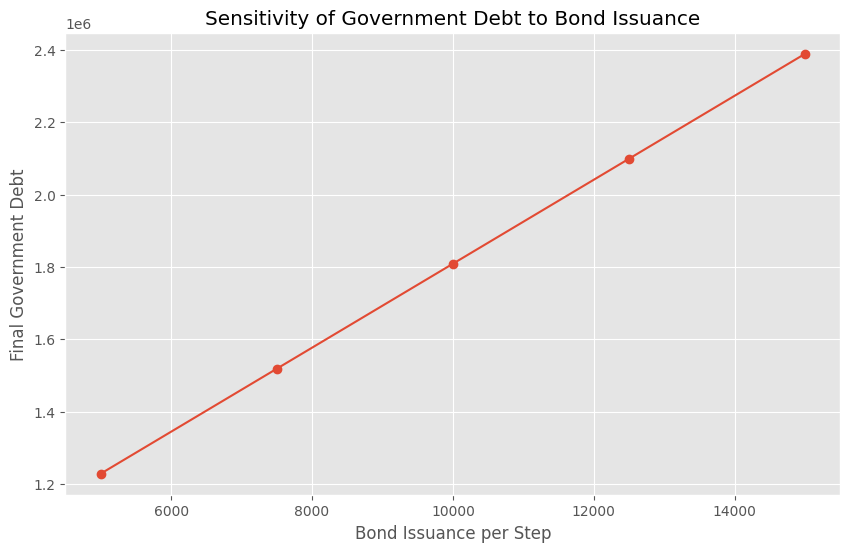

In [43]:
plt.figure(figsize=(10,6))

plt.plot(
    sensitivity_df["Bond_Issuance"],
    sensitivity_df["Final_Debt"],
    marker="o"
)

plt.xlabel("Bond Issuance per Step")
plt.ylabel("Final Government Debt")
plt.title("Sensitivity of Government Debt to Bond Issuance")
plt.grid(True)
plt.show()

## **Robustness Analysis**

In [44]:
robustness_results = []

for seed in [
    1,
    10,
    42,
    100,
    500
]:

    result = run_scenario(
        bond_issuance=10000,
        interest_rate=0.03,
        seed=seed
    )

    result["Seed"] = seed

    robustness_results.append(result)

robustness_df = pd.DataFrame(
    robustness_results
)

display(robustness_df)

robustness_summary = robustness_df[
    [
        "Final_Debt",
        "Final_Yield",
        "Investor_Wealth",
        "Bank_Capital"
    ]
].describe().T

display(robustness_summary)

,Bond_Issuance,Interest_Rate,Final_Debt,Final_Yield,Investor_Wealth,Bank_Capital,Seed
0,10000,0.03,1.808842e+06,4.548704,1496.355287,11573.256840,1
1,10000,0.03,1.808842e+06,4.540364,1208.231896,11669.227232,10
2,10000,0.03,1.808842e+06,4.440271,1246.594674,11349.849153,42
3,10000,0.03,1.808842e+06,4.464716,1310.410046,11467.776445,100
4,10000,0.03,1.808842e+06,4.912715,954.239154,12413.930386,500


,count,mean,std,min,25%,50%,75%,max
Final_Debt,5.0,1.808842e+06,2.603126e-10,1.808842e+06,1.808842e+06,1.808842e+06,1.808842e+06,1.808842e+06
Final_Yield,5.0,4.581354e+00,1.910857e-01,4.440271e+00,4.464716e+00,4.540364e+00,4.548704e+00,4.912715e+00
Investor_Wealth,5.0,1.243166e+03,1.957916e+02,9.542392e+02,1.208232e+03,1.246595e+03,1.310410e+03,1.496355e+03
Bank_Capital,5.0,1.169481e+04,4.192571e+02,1.134985e+04,1.146778e+04,1.157326e+04,1.166923e+04,1.241393e+04


## **Simulation Execution**

In [73]:
np.random.seed(BASE_SEED)
random.seed(BASE_SEED)

model = UKDebtModel()

for _ in range(SIMULATION_STEPS):
    model.step()

print()

print("Final Government Debt :")
print(model.government.debt)

print()

print("Final Bond Yield :")
print(model.government.bond_yield)

print()

print("Average Household Wealth :")
print(
    np.mean([
        h.wealth
        for h in model.households
    ])
)

print()

print("Average Investor Wealth :")
print(
    np.mean([
        i.wealth
        for i in model.investors
    ])
)

print()

print("Average Bank Capital :")
print(
    np.mean([
        b.capital
        for b in model.banks
    ])
)


Final Government Debt :
1808841.57410847

Final Bond Yield :
4.440270692891754

Average Household Wealth :
135500.0

Average Investor Wealth :
1246.594674233878

Average Bank Capital :
11349.849153395615


### **Agent Behaviour Analysis**

In [46]:
behaviour_df = pd.DataFrame({

    "Step": range(
        1,
        SIMULATION_STEPS + 1
    ),

    "Government_Debt":
        model.debt_history,

    "Bond_Yield":
        model.yield_history,

    "Bank_Capital":
        model.bank_capital_history,

    "Investor_Wealth":
        model.investor_wealth_history,

    "Household_Wealth":
        model.household_wealth_history,

    "Bank_Investment":
        model.bank_investment_history,

    "Investor_Investment":
        model.investor_investment_history,

    "Household_Investment":
        model.household_investment_history,

    "Interest_Payment":
        model.interest_payment_history,

    "Bank_Buyers":
        model.bank_buyers_history,

    "Investor_Buyers":
        model.investor_buyers_history,

    "Household_Investors":
        model.household_investors_history
})

display(behaviour_df.head())

,Step,Government_Debt,Bond_Yield,Bank_Capital,Investor_Wealth,Household_Wealth,Bank_Investment,Investor_Investment,Household_Investment,Interest_Payment,Bank_Buyers,Investor_Buyers,Household_Investors
0,1,162320.790000,4.619913,4.000462e+06,86435.434338,51710.0,5.000000e+06,271416.705411,9000.0,4727.790000,5,20,100
1,2,177490.413700,4.623874,3.201202e+06,74835.137468,53420.0,4.000462e+06,232238.821353,9000.0,5169.623700,5,20,100
2,3,193115.126111,4.585177,2.562080e+06,64901.202521,55130.0,3.201202e+06,199000.879370,9000.0,5624.712411,5,20,100
3,4,209208.579894,4.626174,2.051030e+06,56382.842150,56840.0,2.562080e+06,170771.270228,9000.0,6093.453783,5,20,100
4,5,225784.837291,4.668402,1.642394e+06,49068.191666,58550.0,2.051030e+06,146769.278604,9000.0,6576.257397,5,20,100


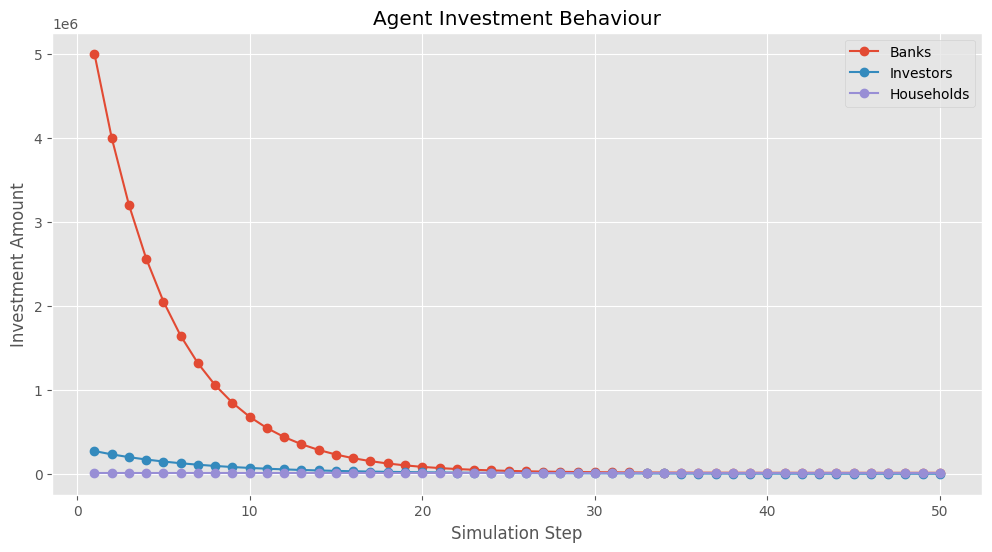

In [47]:
plt.figure(figsize=(12,6))

plt.plot(
    behaviour_df["Step"],
    behaviour_df["Bank_Investment"],
    marker="o",
    label="Banks"
)

plt.plot(
    behaviour_df["Step"],
    behaviour_df["Investor_Investment"],
    marker="o",
    label="Investors"
)

plt.plot(
    behaviour_df["Step"],
    behaviour_df["Household_Investment"],
    marker="o",
    label="Households"
)

plt.xlabel("Simulation Step")
plt.ylabel("Investment Amount")
plt.title("Agent Investment Behaviour")
plt.legend()
plt.grid(True)
plt.show()

In [48]:
# State Transition Analysis

state_transition_df = behaviour_df[
    [
        "Step",
        "Government_Debt",
        "Bond_Yield",
        "Bank_Capital",
        "Investor_Wealth",
        "Household_Wealth"
    ]
].copy()

state_transition_df["Debt_Change"] = (
    state_transition_df["Government_Debt"]
    .diff()
)

state_transition_df["Yield_Change"] = (
    state_transition_df["Bond_Yield"]
    .diff()
)

state_transition_df["Bank_Capital_Change"] = (
    state_transition_df["Bank_Capital"]
    .diff()
)

state_transition_df["Investor_Wealth_Change"] = (
    state_transition_df["Investor_Wealth"]
    .diff()
)

state_transition_df["Household_Wealth_Change"] = (
    state_transition_df["Household_Wealth"]
    .diff()
)

display(
    state_transition_df.head(10)
)

,Step,Government_Debt,Bond_Yield,Bank_Capital,Investor_Wealth,Household_Wealth,Debt_Change,Yield_Change,Bank_Capital_Change,Investor_Wealth_Change,Household_Wealth_Change
0,1,162320.790000,4.619913,4.000462e+06,86435.434338,51710.0,NaN,NaN,NaN,NaN,NaN
1,2,177490.413700,4.623874,3.201202e+06,74835.137468,53420.0,15169.623700,0.003961,-799260.058263,-11600.296870,1710.0
2,3,193115.126111,4.585177,2.562080e+06,64901.202521,55130.0,15624.712411,-0.038696,-639121.450720,-9933.934947,1710.0
3,4,209208.579894,4.626174,2.051030e+06,56382.842150,56840.0,16093.453783,0.040996,-511050.103598,-8518.360371,1710.0
4,5,225784.837291,4.668402,1.642394e+06,49068.191666,58550.0,16576.257397,0.042228,-408636.113252,-7314.650484,1710.0
5,6,242858.382410,4.696138,1.315649e+06,42778.183976,60260.0,17073.545119,0.027736,-326745.304987,-6290.007690,1710.0
6,7,260444.133882,4.715345,1.054384e+06,37361.420453,61970.0,17585.751472,0.019207,-261265.078958,-5416.763524,1710.0
7,8,278557.457899,4.688688,8.454602e+05,32689.502479,63680.0,18113.324016,-0.026657,-208923.731113,-4671.917973,1710.0
8,9,297214.181636,4.674717,6.783944e+05,28654.016582,65390.0,18656.723737,-0.013972,-167065.758899,-4035.485897,1710.0
9,10,316430.607085,4.697737,5.448155e+05,25163.231909,67100.0,19216.425449,0.023020,-133578.890666,-3490.784673,1710.0


# **Critical Model Behaviour Summary**

In [49]:
behaviour_summary = {

    "Initial Government Debt":
        behaviour_df["Government_Debt"].iloc[0],

    "Final Government Debt":
        behaviour_df["Government_Debt"].iloc[-1],

    "Debt Change":
        (
            behaviour_df["Government_Debt"].iloc[-1]
            - behaviour_df["Government_Debt"].iloc[0]
        ),

    "Initial Bond Yield":
        behaviour_df["Bond_Yield"].iloc[0],

    "Final Bond Yield":
        behaviour_df["Bond_Yield"].iloc[-1],

    "Average Bank Investment":
        behaviour_df["Bank_Investment"].mean(),

    "Average Investor Investment":
        behaviour_df["Investor_Investment"].mean(),

    "Average Household Investment":
        behaviour_df["Household_Investment"].mean(),

    "Average Bank Buyers":
        behaviour_df["Bank_Buyers"].mean(),

    "Average Investor Buyers":
        behaviour_df["Investor_Buyers"].mean(),

    "Average Household Investors":
        behaviour_df["Household_Investors"].mean()
}

behaviour_summary_df = pd.DataFrame(
    behaviour_summary.items(),
    columns=["Measure", "Value"]
)

display(behaviour_summary_df)

,Measure,Value
0,Initial Government Debt,1.623208e+05
1,Final Government Debt,1.808842e+06
2,Debt Change,1.646521e+06
3,Initial Bond Yield,4.619913e+00
4,Final Bond Yield,4.945766e+00
5,Average Bank Investment,5.099165e+05
6,Average Investor Investment,4.053033e+04
7,Average Household Investment,9.000000e+03
8,Average Bank Buyers,5.000000e+00
9,Average Investor Buyers,2.000000e+01


## **Government Debt During Simulation**

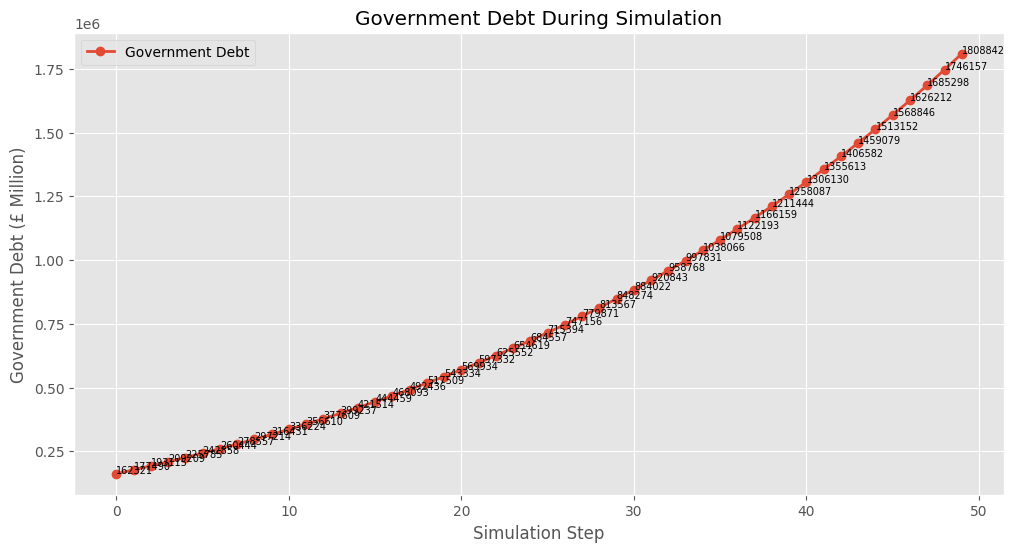

In [50]:
plt.figure(figsize=(12,6))

plt.plot(
    model.debt_history,
    marker="o",
    linewidth=2,
    label="Government Debt"
)

for i, value in enumerate(model.debt_history):

    plt.text(
        i,
        value,
        f"{value:.0f}",
        fontsize=7
    )

plt.title("Government Debt During Simulation")

plt.xlabel("Simulation Step")

plt.ylabel("Government Debt (£ Million)")

plt.grid(True)

plt.legend()

plt.show()

## **Bond Yield During Simulation**

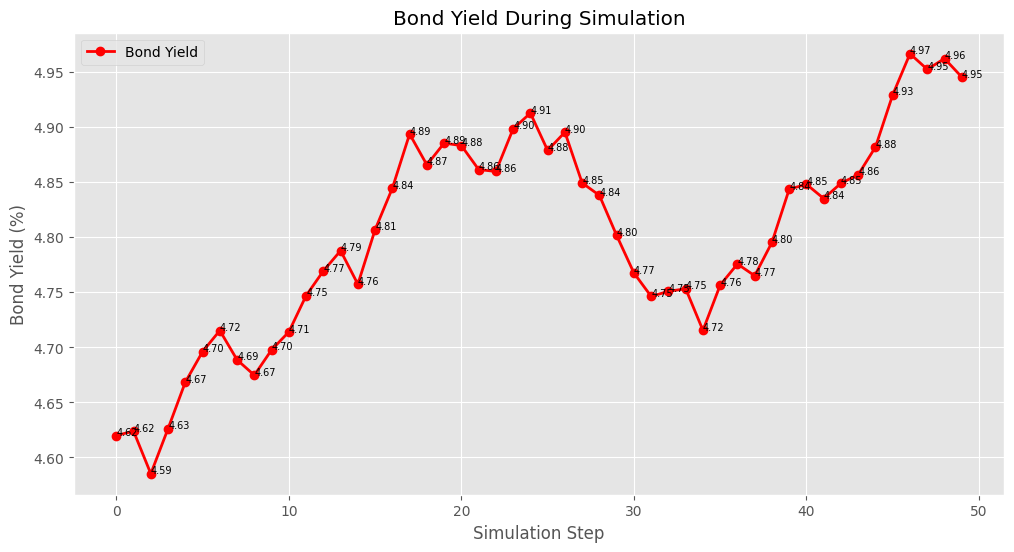

In [51]:
plt.figure(figsize=(12,6))

plt.plot(
    model.yield_history,
    marker="o",
    color="red",
    linewidth=2,
    label="Bond Yield"
)

for i, value in enumerate(model.yield_history):

    plt.text(
        i,
        value,
        f"{value:.2f}",
        fontsize=7
    )

plt.title("Bond Yield During Simulation")

plt.xlabel("Simulation Step")

plt.ylabel("Bond Yield (%)")

plt.grid(True)

plt.legend()

plt.show()

## **Average Household Wealth**

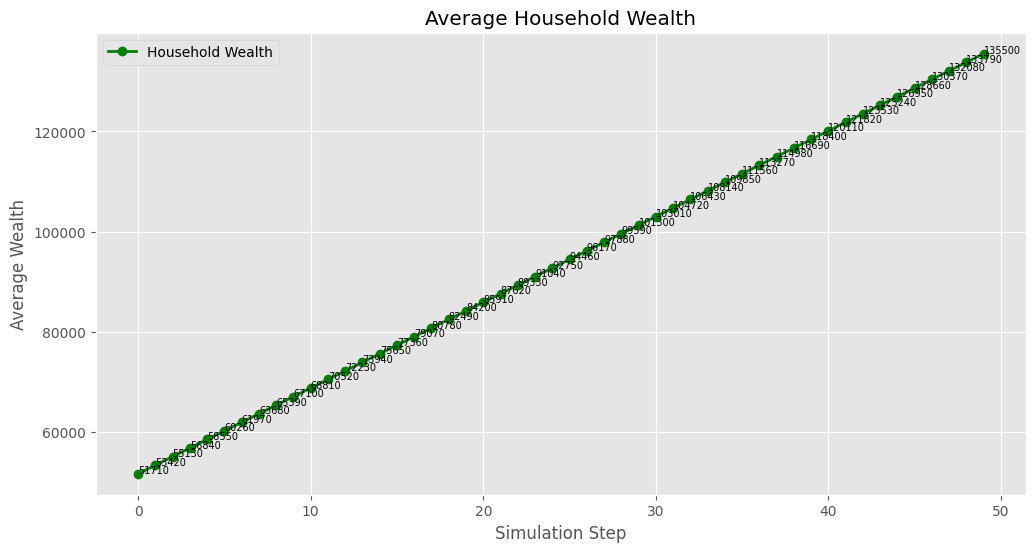

In [52]:
plt.figure(figsize=(12,6))

plt.plot(
    model.household_wealth_history,
    marker="o",
    color="green",
    linewidth=2,
    label="Household Wealth"
)

for i, value in enumerate(model.household_wealth_history):

    plt.text(
        i,
        value,
        f"{value:.0f}",
        fontsize=7
    )

plt.title("Average Household Wealth")

plt.xlabel("Simulation Step")

plt.ylabel("Average Wealth")

plt.grid(True)

plt.legend()

plt.show()

## **Average Investor Wealth**

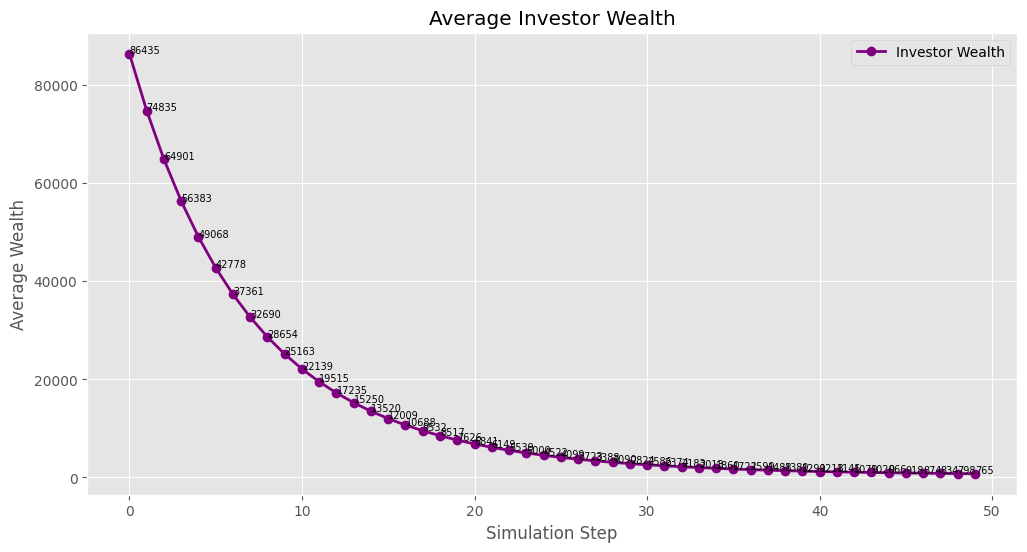

In [53]:
plt.figure(figsize=(12,6))

plt.plot(
    model.investor_wealth_history,
    marker="o",
    color="purple",
    linewidth=2,
    label="Investor Wealth"
)

for i, value in enumerate(model.investor_wealth_history):

    plt.text(
        i,
        value,
        f"{value:.0f}",
        fontsize=7
    )

plt.title("Average Investor Wealth")

plt.xlabel("Simulation Step")

plt.ylabel("Average Wealth")

plt.grid(True)

plt.legend()

plt.show()

## **Average Bank Capital**

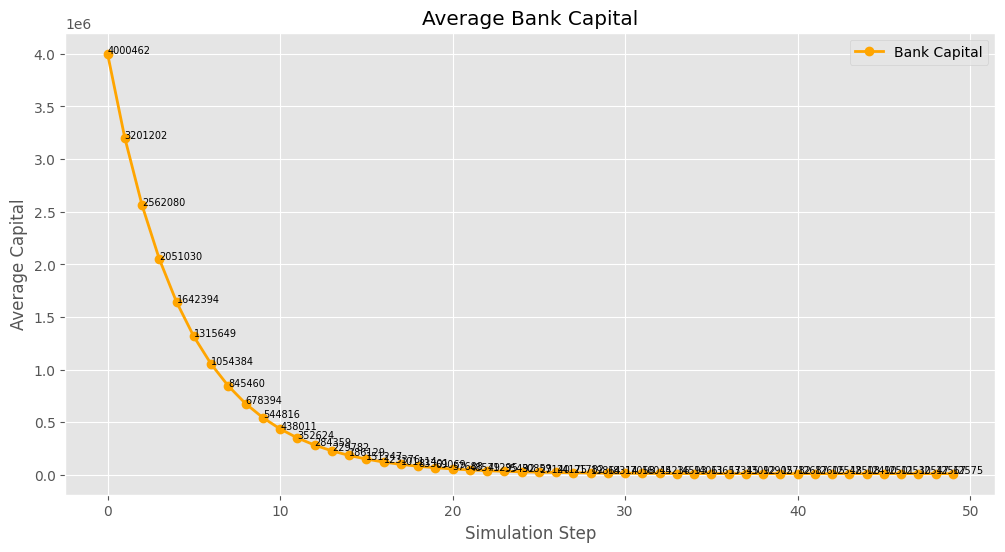

In [54]:
plt.figure(figsize=(12,6))

plt.plot(
    model.bank_capital_history,
    marker="o",
    color="orange",
    linewidth=2,
    label="Bank Capital"
)

for i, value in enumerate(model.bank_capital_history):

    plt.text(
        i,
        value,
        f"{value:.0f}",
        fontsize=7
    )

plt.title("Average Bank Capital")

plt.xlabel("Simulation Step")

plt.ylabel("Average Capital")

plt.grid(True)

plt.legend()

plt.show()

# **Monte Carlo Simulation**

## **Monte Carlo Simulation**

In [55]:
def run_single_simulation(
    seed,
    steps=SIMULATION_STEPS
):

    # Reproducibility
    np.random.seed(seed)
    random.seed(seed)

    model = UKDebtModel()


    for _ in range(steps):

        model.step()

    return {

        "Government_Debt":
            model.government.debt,

        "Bond_Yield":
            model.government.bond_yield,

        "Household_Wealth":
            np.mean([
                h.wealth
                for h in model.households
            ]),

        "Investor_Wealth":
            np.mean([
                i.wealth
                for i in model.investors
            ]),

        "Bank_Capital":
            np.mean([
                b.capital
                for b in model.banks
            ])
    }

# Executing Monte Carlo replications

simulation_results = []

for run in range(MONTE_CARLO_RUNS):

    result = run_single_simulation(
        seed=BASE_SEED + run
    )

    result["Run"] = run + 1

    simulation_results.append(result)


# Converting results to DataFrame
simulation_results = pd.DataFrame(
    simulation_results
)

simulation_results = simulation_results[
    [
        "Run",
        "Government_Debt",
        "Bond_Yield",
        "Household_Wealth",
        "Investor_Wealth",
        "Bank_Capital"
    ]
]

display(
    simulation_results.head()
)

print(
    "Simulation Runs Completed :",
    len(simulation_results)
)

,Run,Government_Debt,Bond_Yield,Household_Wealth,Investor_Wealth,Bank_Capital
0,1,1.808842e+06,4.440271,135500.0,1246.594674,11349.849153
1,2,1.808842e+06,4.757666,135500.0,1396.028588,12320.687761
2,3,1.808842e+06,4.521439,135500.0,841.830070,11594.749616
3,4,1.808842e+06,4.231875,135500.0,1045.452049,11029.940302
4,5,1.808842e+06,4.061027,135500.0,949.087551,10353.528885


Simulation Runs Completed : 100


## **Monte Carlo Convergence Analysis**

In [56]:
# Monte Carlo Convergence Analysis

RUN_COUNTS = [10, 25, 50, 100, 250, 500]

convergence_results = []

for n_runs in RUN_COUNTS:

    results = []

    for run in range(n_runs):

        result = run_single_simulation(
            seed=BASE_SEED + run
        )

        results.append(result)

    temp = pd.DataFrame(results)

    for variable in [
        "Bond_Yield",
        "Investor_Wealth",
        "Bank_Capital"
    ]:

        values = temp[variable]

        mean_value = values.mean()
        sd_value = values.std()
        se_value = stats.sem(values)

        ci_low, ci_high = stats.t.interval(
            0.95,
            len(values) - 1,
            loc=mean_value,
            scale=se_value
        )

        convergence_results.append({

            "Runs": n_runs,
            "Variable": variable,
            "Mean": mean_value,
            "SD": sd_value,
            "SE": se_value,
            "CI_Lower": ci_low,
            "CI_Upper": ci_high,
            "CI_Width": ci_high - ci_low
        })

convergence_df = pd.DataFrame(
    convergence_results
)

display(convergence_df)

,Runs,Variable,Mean,SD,SE,CI_Lower,CI_Upper,CI_Width
0,10,Bond_Yield,4.497333,0.254052,0.080338,4.315595,4.679071,0.363476
1,10,Investor_Wealth,1077.191254,221.763042,70.127631,918.551531,1235.830978,317.279447
2,10,Bank_Capital,11536.865441,623.774817,197.254917,11090.643818,11983.087065,892.443247
3,25,Bond_Yield,4.540315,0.248548,0.049710,4.437719,4.642910,0.205191
4,25,Investor_Wealth,1121.588480,173.318672,34.663734,1050.046049,1193.130912,143.084863
5,25,Bank_Capital,11603.089661,591.381848,118.276370,11358.979231,11847.200090,488.220858
6,50,Bond_Yield,4.543581,0.230971,0.032664,4.477940,4.609223,0.131283
7,50,Investor_Wealth,1084.282493,172.830027,24.441857,1035.164743,1133.400243,98.235500
8,50,Bank_Capital,11611.404604,564.648413,79.853344,11450.933301,11771.875907,320.942607
9,100,Bond_Yield,4.547158,0.210529,0.021053,4.505385,4.588932,0.083547


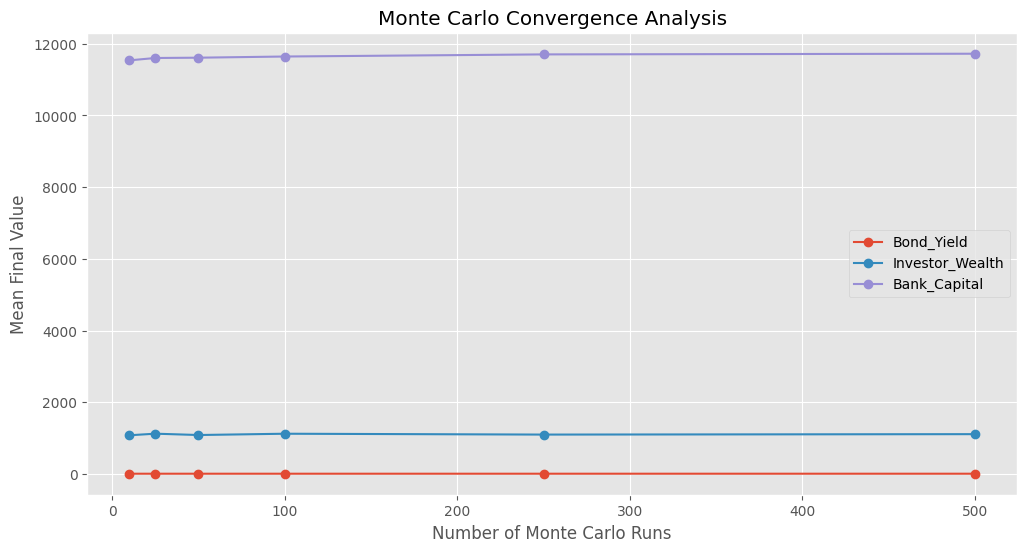

In [57]:
# Mean convergence

plt.figure(figsize=(12,6))

for variable in [
    "Bond_Yield",
    "Investor_Wealth",
    "Bank_Capital"
]:

    subset = convergence_df[
        convergence_df["Variable"] == variable
    ]

    plt.plot(
        subset["Runs"],
        subset["Mean"],
        marker="o",
        label=variable
    )

plt.xlabel("Number of Monte Carlo Runs")
plt.ylabel("Mean Final Value")
plt.title("Monte Carlo Convergence Analysis")
plt.legend()
plt.grid(True)
plt.show()

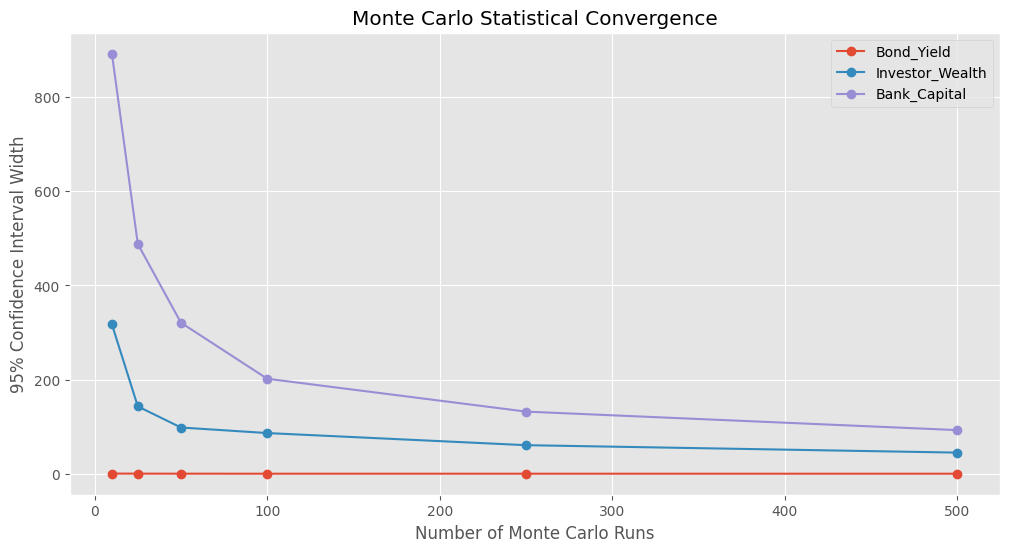

In [58]:
# Confidence Interval Width Convergence

plt.figure(figsize=(12,6))

for variable in [
    "Bond_Yield",
    "Investor_Wealth",
    "Bank_Capital"
]:

    subset = convergence_df[
        convergence_df["Variable"] == variable
    ]

    plt.plot(
        subset["Runs"],
        subset["CI_Width"],
        marker="o",
        label=variable
    )

plt.xlabel("Number of Monte Carlo Runs")
plt.ylabel("95% Confidence Interval Width")
plt.title("Monte Carlo Statistical Convergence")
plt.legend()
plt.grid(True)
plt.show()

## **Monte Carlo Statistical Summary**

In [59]:
summary = simulation_results.describe().T

summary["SE"] = (
    summary["std"]
    / np.sqrt(summary["count"])
)

summary["CV_%"] = (
    summary["std"]
    / summary["mean"]
) * 100

display(summary)

summary.to_csv(
    "MonteCarlo_Summary.csv"
)

,count,mean,std,min,25%,50%,75%,max,SE,CV_%
Run,100.0,5.050000e+01,2.901149e+01,1.000000e+00,2.575000e+01,5.050000e+01,7.525000e+01,1.000000e+02,2.901149e+00,5.744850e+01
Government_Debt,100.0,1.808842e+06,9.360144e-10,1.808842e+06,1.808842e+06,1.808842e+06,1.808842e+06,1.808842e+06,9.360144e-11,5.174662e-14
Bond_Yield,100.0,4.547158e+00,2.105294e-01,4.030376e+00,4.417425e+00,4.541421e+00,4.678135e+00,5.061974e+00,2.105294e-02,4.629912e+00
Household_Wealth,100.0,1.355000e+05,0.000000e+00,1.355000e+05,1.355000e+05,1.355000e+05,1.355000e+05,1.355000e+05,0.000000e+00,0.000000e+00
Investor_Wealth,100.0,1.120412e+03,2.178481e+02,6.175295e+02,9.693340e+02,1.099816e+03,1.285519e+03,1.766790e+03,2.178481e+01,1.944357e+01
Bank_Capital,100.0,1.164416e+04,5.086769e+02,1.035353e+04,1.134746e+04,1.160697e+04,1.198239e+04,1.295576e+04,5.086769e+01,4.368516e+00


## **Average Simulation Results**

In [60]:
print("Average Government Debt :")

print(simulation_results["Government_Debt"].mean())

print()

print("Average Bond Yield :")

print(simulation_results["Bond_Yield"].mean())

print()

print("Average Household Wealth :")

print(simulation_results["Household_Wealth"].mean())

print()

print("Average Investor Wealth :")

print(simulation_results["Investor_Wealth"].mean())

print()

print("Average Bank Capital :")

print(simulation_results["Bank_Capital"].mean())

Average Government Debt :
1808841.5741084705

Average Bond Yield :
4.547158249084691

Average Household Wealth :
135500.0

Average Investor Wealth :
1120.4123230439718

Average Bank Capital :
11644.156089859305


## **Statistical Evaluation**

In [61]:
confidence_results = []

for column in [
    "Government_Debt",
    "Bond_Yield",
    "Household_Wealth",
    "Investor_Wealth",
    "Bank_Capital"
]:

    values = simulation_results[column]

    mean_value = values.mean()
    sd_value = values.std()

    if sd_value == 0:

        se_value = 0
        ci_low = mean_value
        ci_high = mean_value

    else:

        se_value = stats.sem(values)

        ci_low, ci_high = stats.t.interval(
            0.95,
            len(values) - 1,
            loc=mean_value,
            scale=se_value
        )

    confidence_results.append({

        "Variable": column,

        "Mean": mean_value,

        "SD": sd_value,

        "SE": se_value,

        "95% CI Lower": ci_low,

        "95% CI Upper": ci_high,

        "CI Width": ci_high - ci_low
    })

confidence_df = pd.DataFrame(
    confidence_results
)

display(confidence_df)

,Variable,Mean,SD,SE,95% CI Lower,95% CI Upper,CI Width
0,Government_Debt,1.808842e+06,9.360144e-10,4.680072e-11,1.808842e+06,1.808842e+06,0.000000
1,Bond_Yield,4.547158e+00,2.105294e-01,2.105294e-02,4.505385e+00,4.588932e+00,0.083547
2,Household_Wealth,1.355000e+05,0.000000e+00,0.000000e+00,1.355000e+05,1.355000e+05,0.000000
3,Investor_Wealth,1.120412e+03,2.178481e+02,2.178481e+01,1.077187e+03,1.163638e+03,86.451590
4,Bank_Capital,1.164416e+04,5.086769e+02,5.086769e+01,1.154322e+04,1.174509e+04,201.865056


## **Monte Carlo Visualisation**

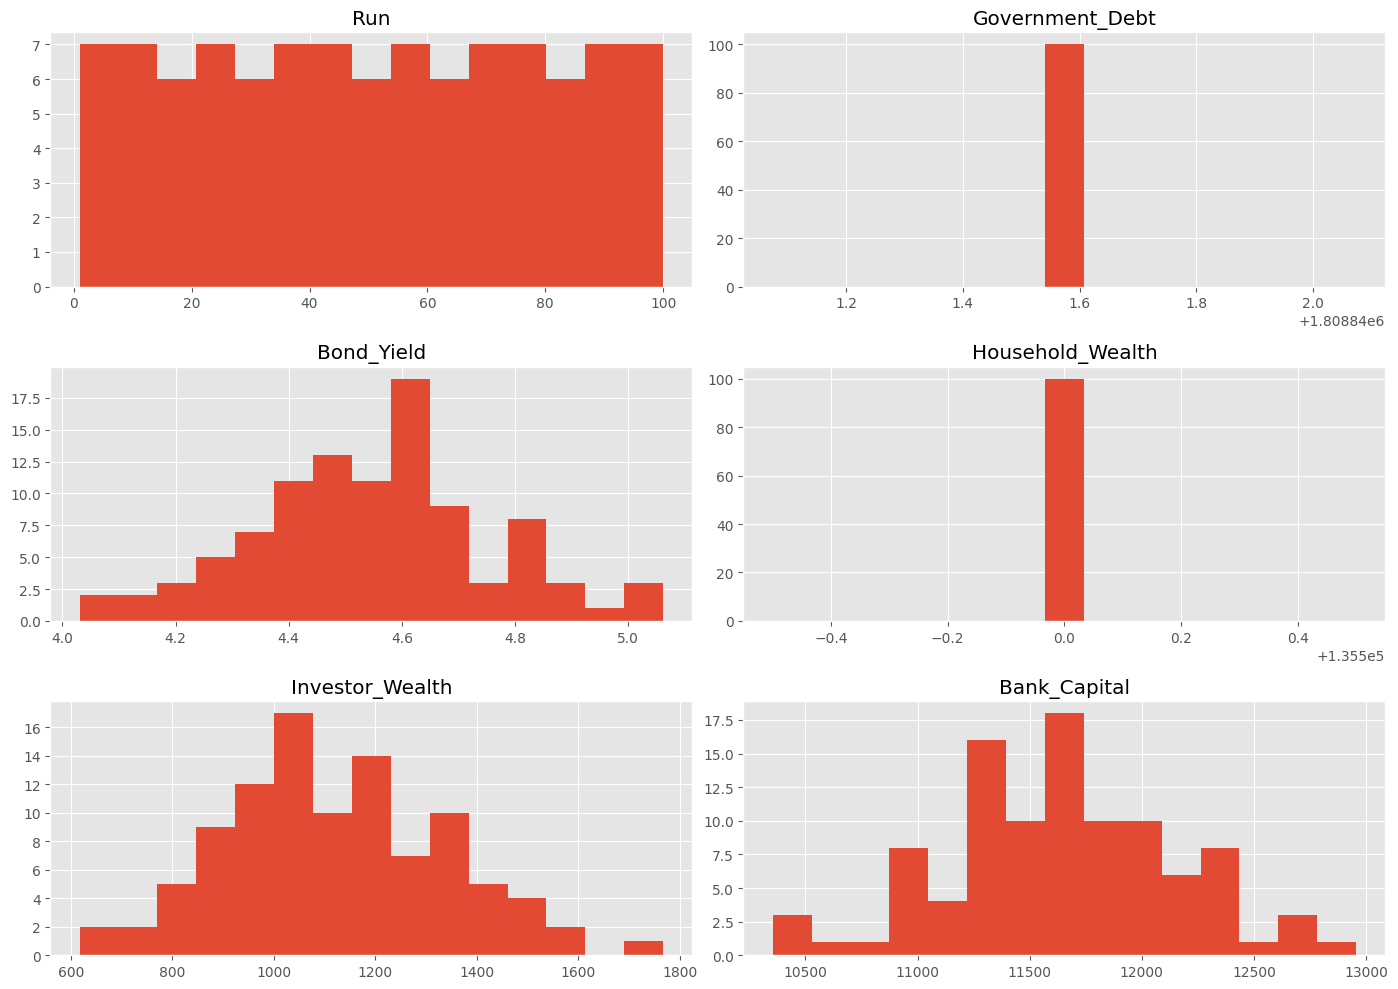

In [62]:
simulation_results.hist(

    figsize=(14,10),

    bins=15

)

plt.tight_layout()

plt.show()

## **Normalized Monte Carlo Results**

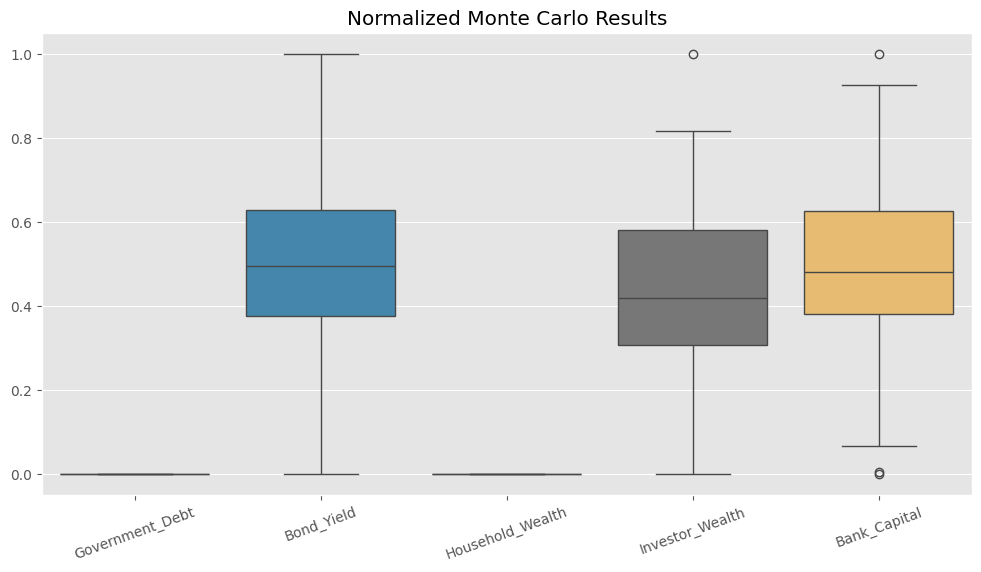

In [63]:
from sklearn.preprocessing import MinMaxScaler

scaled = pd.DataFrame(
    MinMaxScaler().fit_transform(
        simulation_results.drop(columns=["Run"])
    ),
    columns=simulation_results.columns[1:]
)

plt.figure(figsize=(12,6))

sns.boxplot(data=scaled)

plt.title("Normalized Monte Carlo Results")

plt.xticks(rotation=20)

plt.show()

# **Network Analysis of Economic Agents**

## **Economic Network Construction**

In [64]:
G = nx.Graph()

# Adding Government
G.add_node("Government", node_type="Government")

# Adding Banks
for i in range(NUM_BANKS):

    G.add_node(f"Bank_{i+1}", node_type="Bank")

# Adding Investors
for i in range(NUM_INVESTORS):

    G.add_node(f"Investor_{i+1}", node_type="Investor")

# Adding Households
for i in range(NUM_HOUSEHOLDS):

    G.add_node(f"Household_{i+1}", node_type="Household")

print("Total Nodes :", G.number_of_nodes())
print("Total Edges :", G.number_of_edges())

Total Nodes : 126
Total Edges : 0


In [65]:
# Government <-> Banks

for i in range(NUM_BANKS):

    G.add_edge("Government", f"Bank_{i+1}")


# Government <-> Investors

for i in range(NUM_INVESTORS):

    G.add_edge("Government", f"Investor_{i+1}")


# Government <-> Households

for i in range(NUM_HOUSEHOLDS):

    G.add_edge("Government", f"Household_{i+1}")

print("Edges Created :", G.number_of_edges())

Edges Created : 125


## **Network Visualisation**

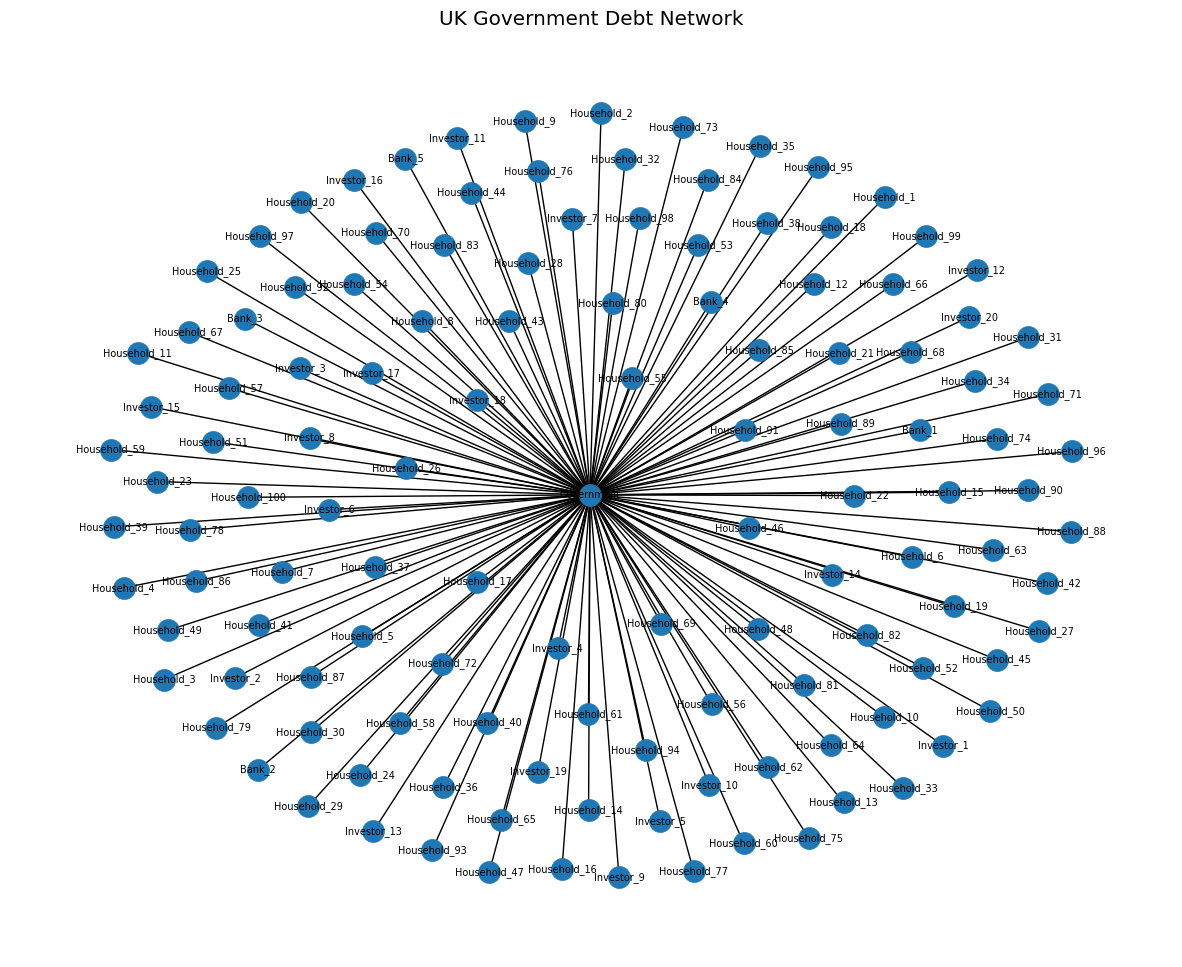

In [66]:
plt.figure(figsize=(15,12))

pos = nx.spring_layout(
    G,
    seed=42
)

nx.draw_networkx(

    G,

    pos,

    node_size=250,

    font_size=7,

    with_labels=True

)

plt.title("UK Government Debt Network")

plt.axis("off")

plt.show()

## **Centrality Analysis**

In [67]:
degree = nx.degree_centrality(G)

degree_df = pd.DataFrame({

    "Node": degree.keys(),

    "Degree_Centrality": degree.values()

})

degree_df = degree_df.sort_values(

    "Degree_Centrality",

    ascending=False

)

display(degree_df.head(20))

,Node,Degree_Centrality
0,Government,1.000
1,Bank_1,0.008
2,Bank_2,0.008
3,Bank_3,0.008
4,Bank_4,0.008
5,Bank_5,0.008
6,Investor_1,0.008
7,Investor_2,0.008
8,Investor_3,0.008
9,Investor_4,0.008


In [68]:
between = nx.betweenness_centrality(G)

between_df = pd.DataFrame({

    "Node": between.keys(),

    "Betweenness": between.values()

})

between_df = between_df.sort_values(

    "Betweenness",

    ascending=False

)

display(between_df.head(20))

,Node,Betweenness
0,Government,1.0
1,Bank_1,0.0
2,Bank_2,0.0
3,Bank_3,0.0
4,Bank_4,0.0
5,Bank_5,0.0
6,Investor_1,0.0
7,Investor_2,0.0
8,Investor_3,0.0
9,Investor_4,0.0


In [69]:
close = nx.closeness_centrality(G)

close_df = pd.DataFrame({

    "Node": close.keys(),

    "Closeness": close.values()

})

close_df = close_df.sort_values(

    "Closeness",

    ascending=False

)

display(close_df.head(20))

,Node,Closeness
0,Government,1.000000
1,Bank_1,0.502008
2,Bank_2,0.502008
3,Bank_3,0.502008
4,Bank_4,0.502008
5,Bank_5,0.502008
6,Investor_1,0.502008
7,Investor_2,0.502008
8,Investor_3,0.502008
9,Investor_4,0.502008


## **Network Comparison**

In [70]:
centrality = degree_df.merge(

    between_df,

    on="Node"

)

centrality = centrality.merge(

    close_df,

    on="Node"

)

display(centrality.head(20))

,Node,Degree_Centrality,Betweenness,Closeness
0,Government,1.000,1.0,1.000000
1,Bank_1,0.008,0.0,0.502008
2,Bank_2,0.008,0.0,0.502008
3,Bank_3,0.008,0.0,0.502008
4,Bank_4,0.008,0.0,0.502008
5,Bank_5,0.008,0.0,0.502008
6,Investor_1,0.008,0.0,0.502008
7,Investor_2,0.008,0.0,0.502008
8,Investor_3,0.008,0.0,0.502008
9,Investor_4,0.008,0.0,0.502008


## **Most Influential Economic Agents**

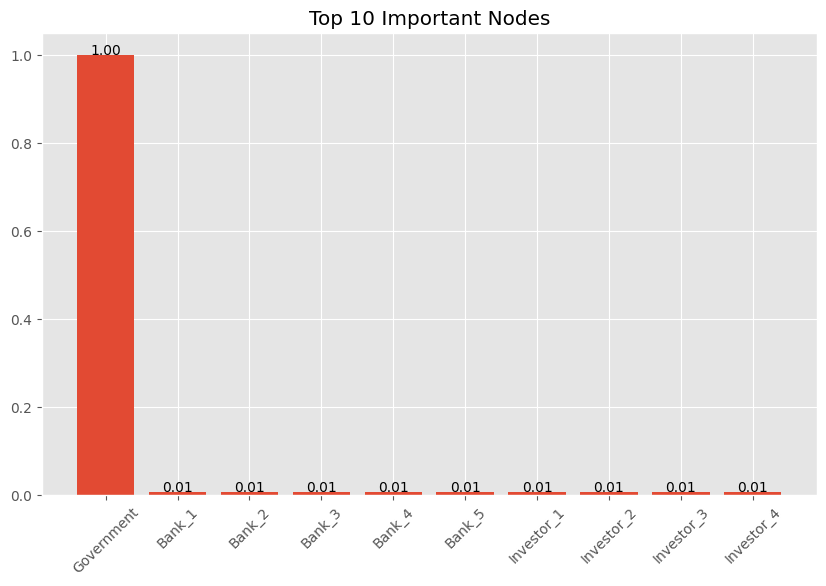

In [71]:
top = centrality.sort_values(

    "Degree_Centrality",

    ascending=False

).head(10)

plt.figure(figsize=(10,6))

bars = plt.bar(

    top["Node"],

    top["Degree_Centrality"]

)

plt.title("Top 10 Important Nodes")

plt.xticks(rotation=45)

for bar in bars:

    y = bar.get_height()

    plt.text(

        bar.get_x()+bar.get_width()/2,

        y,

        f"{y:.2f}",

        ha="center"

    )

plt.show()

In [72]:
simulation_results.to_csv("simulation_results.csv", index=False)